In [1]:
!pip install pandas numpy scikit-learn xgboost optuna shap matplotlib seaborn

# Phase 5-8: EDA, Feature Engineering & Target Validation

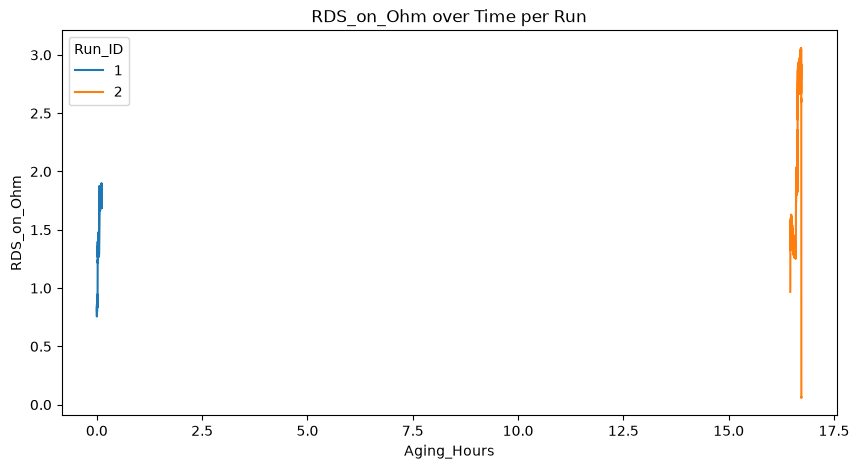

   Run_ID  Value_0h  Value_2h  Delta_Value  Early_Slope  Target_Value
0       1  0.826059  1.716772     0.890714     0.445357      1.716772
1       2  0.967668  0.967668     0.000000     0.000000      0.062071


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv('/Users/anshul/Documents/AI/data/raw/MOSFET/MOSFET_Device_01.csv')

# EDA
plt.figure(figsize=(10, 5))
sns.lineplot(data=df, x='Aging_Hours', y='RDS_on_Ohm', hue='Run_ID', palette='tab10')
plt.title('RDS_on_Ohm over Time per Run')
plt.show()

# Feature Engineering
# Since we don't have 168 hours, we'll extract features for early hours (e.g., 0 to 2) and predict the last hour (e.g., 16).
features = []
for run_id, group in df.groupby('Run_ID'):
    group = group.sort_values('Aging_Hours')
    
    val_0h = group.iloc[0]['RDS_on_Ohm']
    
    # closest to 2 hours
    idx_2h = (group['Aging_Hours'] - 2.0).abs().idxmin()
    val_2h = group.loc[idx_2h, 'RDS_on_Ohm']
    
    # target: last available value (approx 16h)
    val_target = group.iloc[-1]['RDS_on_Ohm']
    
    delta = val_2h - val_0h
    slope = delta / 2.0
    
    features.append({
        'Run_ID': run_id,
        'Value_0h': val_0h,
        'Value_2h': val_2h,
        'Delta_Value': delta,
        'Early_Slope': slope,
        'Target_Value': val_target
    })

feat_df = pd.DataFrame(features)
print(feat_df)
feat_df.to_csv('/Users/anshul/Documents/AI/data/raw/MOSFET/engineered_features.csv', index=False)
